In [1]:
import os
from datetime import time

import geopandas as gpd
import pandas as pd
import gtfs_kit
import contextily as cx
from tqdm import tqdm

import h3
import json
from matplotlib import pyplot as plt
import shapely
from shapely.geometry.point import Point
from shapely.geometry.polygon import Polygon
from shapely.geometry.linestring import LineString

from simulation.environment.geodesic_position import GeodesicPosition
from simulation.environment.geodesic_environment import GeodesicEnvironment

In [2]:
def difference(a, b):
    return tuple(x-y for x, y in zip(a.coords[0], b.coords[0]))

In [3]:
PROJECTPATH = '/Users/janik/source/urban-mobility-simulation'
DATAPATH = os.path.join(PROJECTPATH, 'data')
GTFS_IN = os.path.join(DATAPATH, 'infrastructure/GTFS.zip')
TRANSIT_OUT = os.path.join(DATAPATH, 'infrastructure/transit_timetable.csv')
TRANSIT_SHAPES_OUT = os.path.join(DATAPATH, 'infrastructure/transit_shapes.csv')
CITY_AREA = os.path.join(DATAPATH, 'environment/geodesic/env_districts.geojson')

SCHEMA = ['stop_id', 'stop_lat', 'stop_lon', 'departure_time', 'dep_next_day', 'shape_dist_traveled',
          'route_id', 'service_id', 'trip_id', 'trip_short_name', 'shape_id', 'direction_id', 'stop_sequence',
          'monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday']

# TRIP = 163297125 # direction 0
TRIP = 163296942 # direction 1

In [4]:
timetable = pd.read_csv(TRANSIT_OUT)

In [5]:
route_stops = timetable[timetable['trip_id'] == TRIP]
route_stops = route_stops[~route_stops.duplicated(subset=['stop_lat', 'stop_lon'])]
route_stops = route_stops[~route_stops.duplicated(subset=['stop_sequence'])]
route_stops_sorted = route_stops.sort_values('stop_sequence', ignore_index=True)

origin = GeodesicPosition(latitude=route_stops_sorted.loc[0, 'stop_lat'], longitude=route_stops_sorted.loc[0, 'stop_lon'])
destination = GeodesicPosition(latitude=route_stops_sorted.loc[26, 'stop_lat'], longitude=route_stops_sorted.loc[26, 'stop_lon'])

## Linear Corridor with uniformly distributed checkpoints

In [6]:
env = GeodesicEnvironment.getInstance()
c = env.corridor(origin.get_hexagon_id(resolution=8), destination.get_hexagon_id(resolution=8), 2)

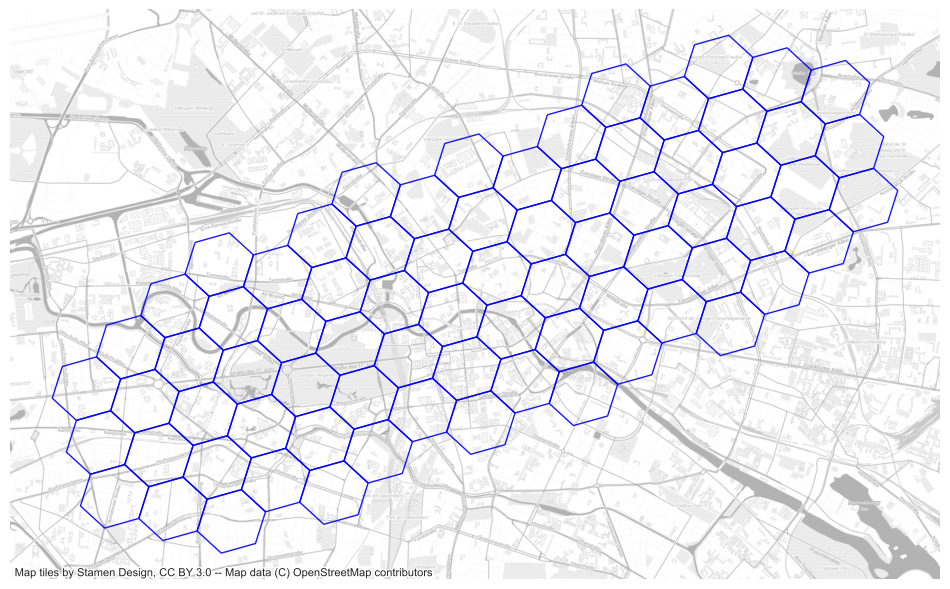

In [7]:
fig, ax = plt.subplots(figsize=(12,10))

# Action Space Hex Resolution 8
hexs_8_gpd = gpd.GeoDataFrame.from_records([{'hex': h, 'geometry': Polygon(h3.h3_to_geo_boundary(h, geo_json=True))} for h in c])
hexs_8_gpd.crs = 'EPSG:4326'
hexs_8_gpd_wm = hexs_8_gpd.to_crs(epsg=3857)
hexs_8_gpd_wm.plot(ax = ax, alpha=.9, facecolor="none", edgecolor='blue')

# add background map
cx.add_basemap(ax, source=cx.providers.Stamen.Toner, alpha=.3)

plt.axis('off')
plt.show()

In [8]:
def make_checkpoints(o: GeodesicPosition, d: GeodesicPosition, n: int):
    diff_od = d.difference(o)
    diff_per_n = tuple(x / (n+1) for x in diff_od)
    for c_i in range(n):
        yield GeodesicPosition(*(x + (c_i+1)*y for x,y in zip(o.getExactLocation(), diff_per_n)))
    # also include the terminal destination (not included in the number of checkpoints)
    yield d


In [9]:
checkpoints = list(make_checkpoints(origin, destination, 3))

/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/pandas/core/dtypes/cast.py:122: ShapelyDeprecationWarning: The array interface is deprecated and will no longer work in Shapely 2.0. Convert the '.coords' to a numpy array instead.
  arr = construct_1d_object_array_from_listlike(values)


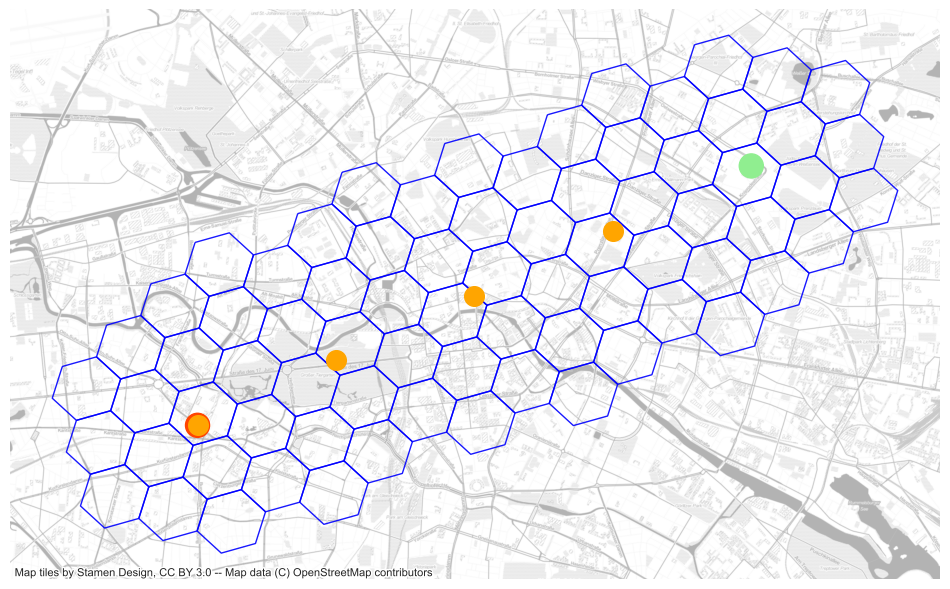

In [10]:
fig, ax = plt.subplots(figsize=(12,10))

# Action Space Hex Resolution 8
hexs_8_gpd = gpd.GeoDataFrame.from_records([{'hex': h, 'geometry': Polygon(h3.h3_to_geo_boundary(h, geo_json=True))} for h in c])
hexs_8_gpd.crs = 'EPSG:4326'
hexs_8_gpd_wm = hexs_8_gpd.to_crs(epsg=3857)
hexs_8_gpd_wm.plot(ax = ax, alpha=.9, facecolor="none", edgecolor='blue')

stops_points = route_stops.sort_values('stop_sequence').apply(lambda x: Point(x['stop_lon'], x['stop_lat']), axis=1)
stops_gpd = gpd.GeoDataFrame.from_records([{'id': k, 'geometry': v} for k, v in enumerate(stops_points)])
stops_gpd.crs = 'EPSG:4326'
stops_gpd_wm = stops_gpd.to_crs(epsg=3857)

stops_gpd_wm['color'] = 'none'
stops_gpd_wm['markersize'] = 0
stops_gpd_wm.loc[0,'color'] = 'lightgreen'
stops_gpd_wm.loc[0, 'markersize'] = 300
stops_gpd_wm.loc[26,'color'] = 'orangered'
stops_gpd_wm.loc[26, 'markersize'] = 300

stops_gpd_wm.plot(ax=ax, c=stops_gpd_wm['color'], markersize=stops_gpd_wm['markersize'], alpha=1, marker='o')

checkpoints_gpd = gpd.GeoDataFrame.from_records([{'id': k, 'geometry': Point(v.getExactLocation(geojson=True))} for k, v in enumerate(checkpoints)])
checkpoints_gpd.crs = 'EPSG:4326'
checkpoints_gpd_wm = checkpoints_gpd.to_crs(epsg=3857)
checkpoints_gpd_wm.plot(ax=ax, c='orange', markersize=200, alpha=1, marker='o')

# add background map
cx.add_basemap(ax, source=cx.providers.Stamen.Toner, alpha=.3)

plt.axis('off')
plt.show()

In [11]:
checkpoints

## Non-linear Corridor with manual checkpoints

/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/pandas/core/dtypes/cast.py:122: ShapelyDeprecationWarning: The array interface is deprecated and will no longer work in Shapely 2.0. Convert the '.coords' to a numpy array instead.
  arr = construct_1d_object_array_from_listlike(values)


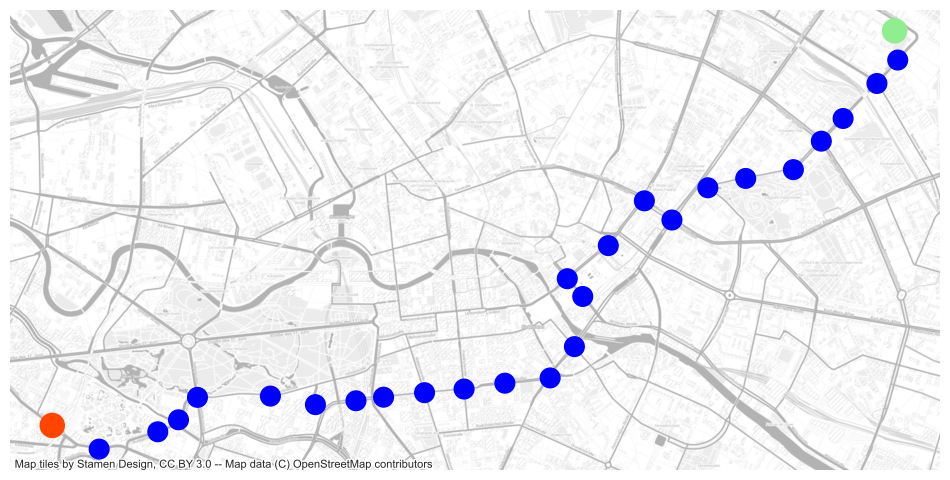

In [11]:
fig, ax = plt.subplots(figsize=(12,10))

stops_points = route_stops.sort_values('stop_sequence').apply(lambda x: Point(x['stop_lon'], x['stop_lat']), axis=1)
stops_gpd = gpd.GeoDataFrame.from_records([{'id': k, 'geometry': v} for k, v in enumerate(stops_points)])
stops_gpd.crs = 'EPSG:4326'
stops_gpd_wm = stops_gpd.to_crs(epsg=3857)

stops_gpd_wm['color'] = 'blue'
stops_gpd_wm['markersize'] = 200
stops_gpd_wm.loc[0,'color'] = 'lightgreen'
stops_gpd_wm.loc[0, 'markersize'] = 300
stops_gpd_wm.loc[26,'color'] = 'orangered'
stops_gpd_wm.loc[26, 'markersize'] = 300
stops_gpd_wm.plot(ax=ax, c=stops_gpd_wm['color'], markersize=stops_gpd_wm['markersize'], alpha=1)

# add background map
cx.add_basemap(ax, source=cx.providers.Stamen.Toner, alpha=.3)

plt.axis('off')
plt.show()

/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/pandas/core/dtypes/cast.py:122: ShapelyDeprecationWarning: The array interface is deprecated and will no longer work in Shapely 2.0. Convert the '.coords' to a numpy array instead.
  arr = construct_1d_object_array_from_listlike(values)
/var/folders/tm/rzk5w14x43s6q7sgpkq2r7wc0000gn/T/ipykernel_6009/1154313513.py:30: ShapelyDeprecationWarning: __getitem__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  [l.parallel_offset(0.01, 'right').boundary[0],
/var/folders/tm/rzk5w14x43s6q7sgpkq2r7wc0000gn/T/ipykernel_6009/1154313513.py:31: ShapelyDeprecationWarning: __getitem__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  l.parallel_offset(0.01, 'right').boundary[1]]
/var/folders/tm/rzk5w14

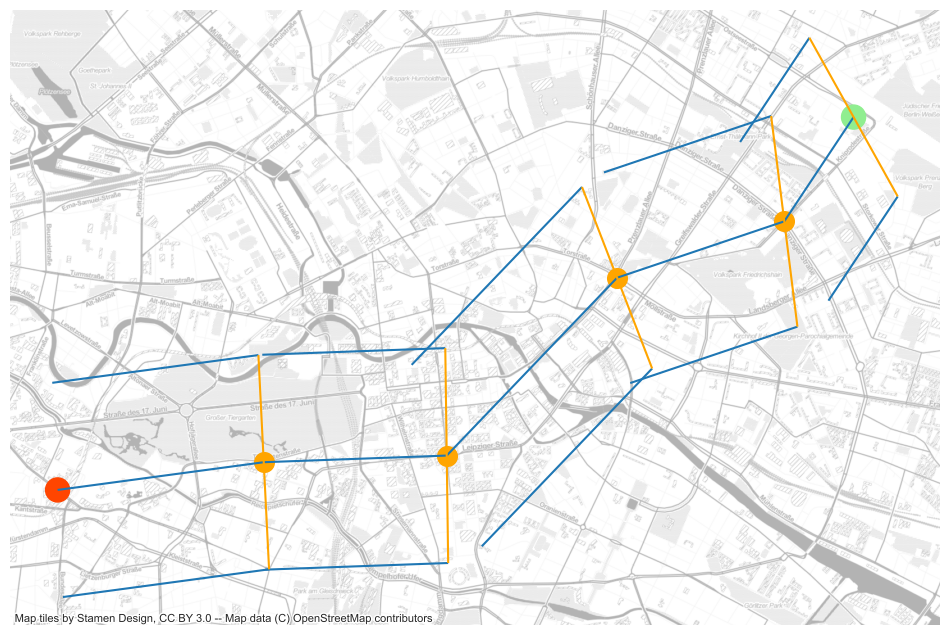

In [12]:
CHECKPOINTS = [5, 10, 17, 22] # starts at 1, origin = 0

checkpoints_w_od = [0] + CHECKPOINTS + [route_stops['stop_sequence'].max()]

stops_checkpoints = route_stops_sorted[route_stops_sorted['stop_sequence'].isin(checkpoints_w_od)].set_index('stop_sequence')

fig, ax = plt.subplots(figsize=(12,10))

checkpoints_points = stops_checkpoints.apply(lambda x: Point(x['stop_lon'], x['stop_lat']), axis=1)
checkpoints_gpd = gpd.GeoDataFrame.from_records([{'id': k, 'geometry': v} for k, v in enumerate(checkpoints_points)])
checkpoints_gpd.crs = 'EPSG:4326'
checkpoints_gpd_wm = checkpoints_gpd.to_crs(epsg=3857)
checkpoints_gpd_wm.plot(ax=ax, c='orange', markersize=200, alpha=1, marker='o')

stops_gpd_wm['color'] = 'none'
stops_gpd_wm['markersize'] = 0
stops_gpd_wm.loc[0,'color'] = 'lightgreen'
stops_gpd_wm.loc[0, 'markersize'] = 300
stops_gpd_wm.loc[26,'color'] = 'orangered'
stops_gpd_wm.loc[26, 'markersize'] = 300

stops_gpd_wm.plot(ax=ax, c=stops_gpd_wm['color'], markersize=stops_gpd_wm['markersize'], alpha=1, marker='o')

for i in range(len(checkpoints_w_od)):
    l = LineString([checkpoints_points[checkpoints_w_od[i]],
                    checkpoints_points[checkpoints_w_od[i+1]]])
    gpd.GeoSeries(l, crs='EPSG:4326').to_crs(epsg=3857).plot(ax=ax)

    right = gpd.GeoSeries(LineString(
        [l.parallel_offset(0.01, 'right').boundary[0],
         l.parallel_offset(0.01, 'right').boundary[1]]
    ))
    right.crs = 'EPSG:4326'
    right_wm = right.to_crs(epsg=3857)
    right_wm.plot(ax=ax)

    left = gpd.GeoSeries(LineString(
        [l.parallel_offset(0.01, 'left').boundary[0],
         l.parallel_offset(0.01, 'left').boundary[1]]
    ))
    left.crs = 'EPSG:4326'
    left_wm = left.to_crs(epsg=3857)
    left_wm.plot(ax=ax)

    boundary = gpd.GeoSeries(LineString(
        [l.parallel_offset(0.01, 'right').boundary[1],
         l.parallel_offset(0.01, 'left').boundary[0]]
    ))
    boundary.crs = 'EPSG:4326'
    boundary_wm = boundary.to_crs(epsg=3857)
    boundary_wm.plot(ax=ax, color='orange')

    if checkpoints_w_od[i] == checkpoints_w_od[-2]:
        break

# add background map
cx.add_basemap(ax, source=cx.providers.Stamen.Toner, alpha=.3)

plt.axis('off')
plt.show()

/var/folders/tm/rzk5w14x43s6q7sgpkq2r7wc0000gn/T/ipykernel_6009/3150679819.py:9: ShapelyDeprecationWarning: __getitem__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  [l.parallel_offset(0.01, 'right').boundary[0],
/var/folders/tm/rzk5w14x43s6q7sgpkq2r7wc0000gn/T/ipykernel_6009/3150679819.py:10: ShapelyDeprecationWarning: __getitem__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  l.parallel_offset(0.01, 'right').boundary[1]]
/var/folders/tm/rzk5w14x43s6q7sgpkq2r7wc0000gn/T/ipykernel_6009/3150679819.py:15: ShapelyDeprecationWarning: __getitem__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  [l.parallel_offset(0.01, 'left').boundary[0],
/var/folders/tm/

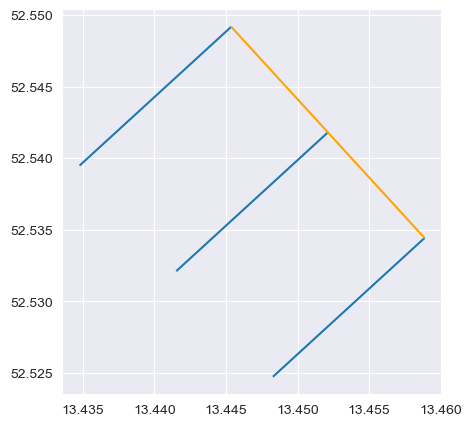

In [13]:
# without projection, it is orthogonal

fig, ax = plt.subplots(figsize=(5,5))

l = LineString([checkpoints_points.iloc[0], checkpoints_points.iloc[1]])
gpd.GeoSeries(l).plot(ax=ax)

right = gpd.GeoSeries(LineString(
    [l.parallel_offset(0.01, 'right').boundary[0],
     l.parallel_offset(0.01, 'right').boundary[1]]
))
right.plot(ax=ax)

left = gpd.GeoSeries(LineString(
    [l.parallel_offset(0.01, 'left').boundary[0],
     l.parallel_offset(0.01, 'left').boundary[1]]
))
left.plot(ax=ax)

boundary = gpd.GeoSeries(LineString(
    [l.parallel_offset(0.01, 'right').boundary[1],
     l.parallel_offset(0.01, 'left').boundary[0]]
))
boundary.plot(ax=ax, color='orange')

plt.show()

### but there is also a cap_style "flat" that does exactly this...

/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/pandas/core/dtypes/cast.py:122: ShapelyDeprecationWarning: The array interface is deprecated and will no longer work in Shapely 2.0. Convert the '.coords' to a numpy array instead.
  arr = construct_1d_object_array_from_listlike(values)


<Figure size 640x480 with 0 Axes>

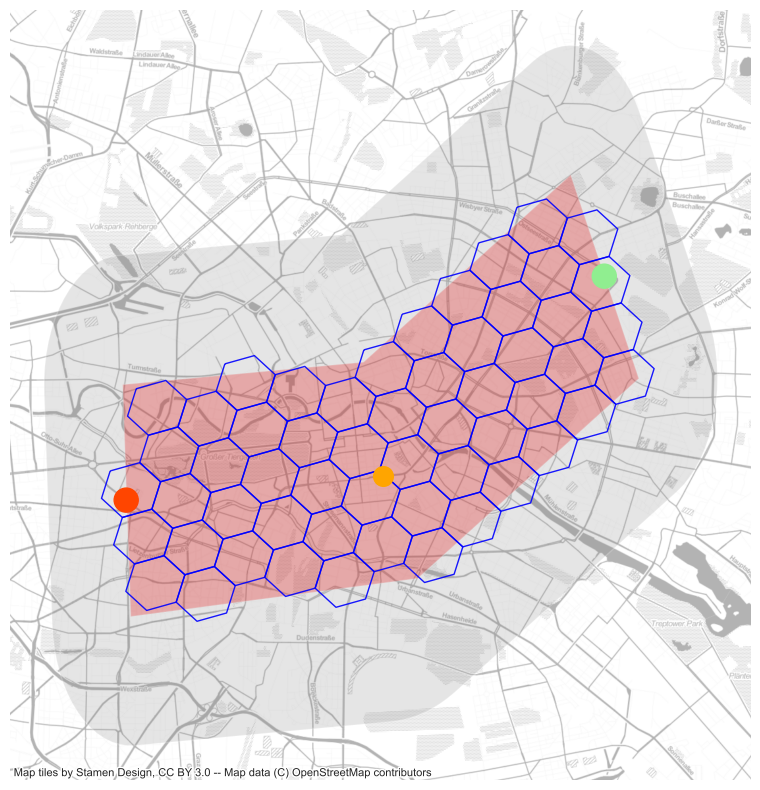

In [14]:
CHECKPOINTS = [16] # starts at 1, origin = 0

checkpoints_w_od = [0] + CHECKPOINTS + [route_stops['stop_sequence'].max()]

stops_checkpoints = route_stops_sorted[route_stops_sorted['stop_sequence'].isin(checkpoints_w_od)].set_index('stop_sequence')

checkpoints_points = stops_checkpoints.apply(lambda x: Point(x['stop_lon'], x['stop_lat']), axis=1)
checkpoints_gpd = gpd.GeoDataFrame.from_records([{'id': k, 'geometry': v} for k, v in enumerate(checkpoints_points)])
checkpoints_gpd.crs = 'EPSG:4326'
checkpoints_gpd_wm = checkpoints_gpd.to_crs(epsg=3857)
checkpoints_gpd_wm.plot(ax=ax, c='orange', markersize=200, alpha=1, marker='o')

# now that we have the route, we need to build two things:
# 1. a demand modifier buffer around it to tune up demand generation around the route for dynamic transit
# 2. an action space that is also a buffer around it, but in higher resolution
# These two should be as similar as possible.

BUFFERSIZE = 0.018
# play around with this until the red area in the plot looks sufficiently polyfilled with green hexagon cells
# the same polyfill will happen in the simulation demand factory
SAFEBUFFER = 0.02
SIMPLIFY_RATIO = 0.002

ACTION_RES = 8

buffer = LineString(
    list(checkpoints_points)).buffer(BUFFERSIZE,
                                     cap_style=shapely.geometry.CAP_STYLE.flat)
safebuffer = gpd.GeoSeries(buffer.buffer(SAFEBUFFER))
simplified_buffer = gpd.GeoSeries(buffer).simplify(SIMPLIFY_RATIO)

fig, ax = plt.subplots(figsize=(12,10))
simplified_buffer.crs = 'EPSG:4326'
simplified_buffer_wm = simplified_buffer.to_crs(epsg=3857)
simplified_buffer_wm.plot(ax=ax, color='red', alpha=.3)
safebuffer.crs = 'EPSG:4326'
safebuffer_wm = safebuffer.to_crs(epsg=3857)
safebuffer_wm.plot(ax=ax, color='grey', alpha=.2)

# Action Space Hex Resolution 8
hexs = h3.polyfill(json.loads(simplified_buffer.to_json())['features'][0]['geometry'], res=ACTION_RES, geo_json_conformant=True)
hexs_gpd = gpd.GeoDataFrame.from_records([{'hex': h, 'geometry': Polygon(h3.h3_to_geo_boundary(h, geo_json=True))} for h in hexs])
hexs_gpd.crs = 'EPSG:4326'
hexs_gpd_wm = hexs_gpd.to_crs(epsg=3857)
hexs_gpd_wm.plot(ax = ax, alpha=.9, facecolor="none", edgecolor='blue')

checkpoints_gpd_wm.plot(ax=ax, c='orange', markersize=200, alpha=1, marker='o')
stops_gpd_wm.plot(ax=ax, c=stops_gpd_wm['color'], markersize=stops_gpd_wm['markersize'], alpha=1, marker='o')

# add background map
cx.add_basemap(ax, source=cx.providers.Stamen.Toner, alpha=.3)

plt.axis('off')
plt.show()

In [15]:
lng, lat = checkpoints_points.iloc[-1].coords[0]
h3.geo_to_h3(lat, lng, ACTION_RES) in hexs

True

In [16]:
# state vector size
len(hexs)*2 + 2*(len(CHECKPOINTS)+1)

114

### Manual, using direction and orthogonal planes to that

/var/folders/tm/rzk5w14x43s6q7sgpkq2r7wc0000gn/T/ipykernel_14176/2776671352.py:17: ShapelyDeprecationWarning: __getitem__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  [o_direction.parallel_offset(0.01, 'right').boundary[1],
/var/folders/tm/rzk5w14x43s6q7sgpkq2r7wc0000gn/T/ipykernel_14176/2776671352.py:18: ShapelyDeprecationWarning: __getitem__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  o_direction.parallel_offset(0.01, 'left').boundary[0]]
/var/folders/tm/rzk5w14x43s6q7sgpkq2r7wc0000gn/T/ipykernel_14176/2776671352.py:23: ShapelyDeprecationWarning: __getitem__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  [d_direction.parallel_offset(0.01, 'rig

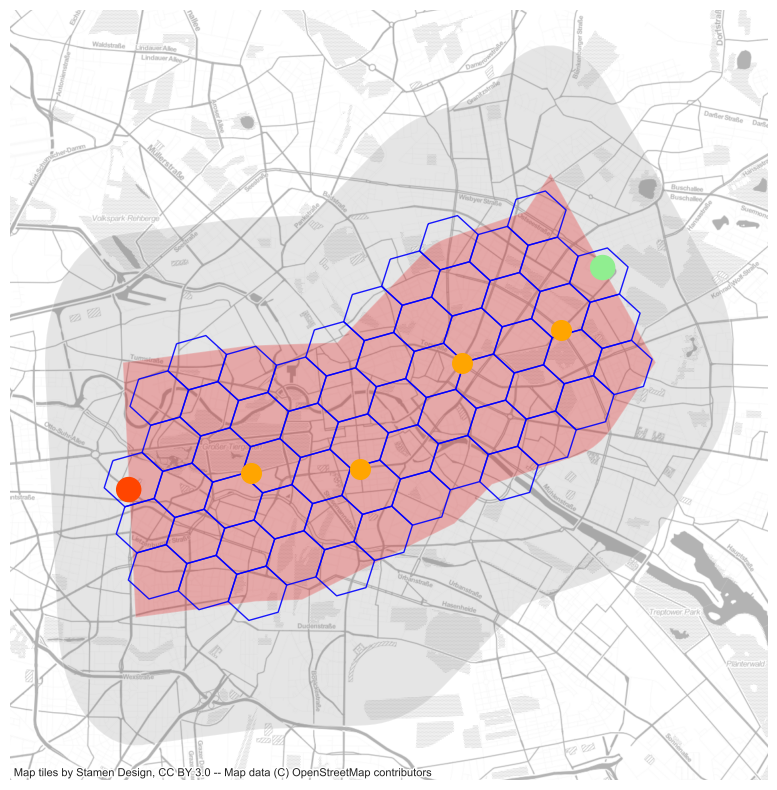

In [26]:
plt.show()
# now that we have the route, we need to build two things:
# 1. a demand modifier buffer around it to tune up demand generation around the route for dynamic transit
# 2. an action space that is also a buffer around it, but in higher resolution
# These two should be as similar as possible.

BUFFERSIZE = 0.02
# play around with this until the red area in the plot looks sufficiently polyfilled with green hexagon cells
# the same polyfill will happen in the simulation demand factory
SAFEBUFFER = 0.02
SIMPLIFY_RATIO = 0.0

ACTION_RES = 8

o_direction = LineString([checkpoints_points.iloc[0], checkpoints_points.iloc[1]])
o_boundary = LineString(
    [o_direction.parallel_offset(0.01, 'right').boundary[1],
     o_direction.parallel_offset(0.01, 'left').boundary[0]]
)

d_direction = LineString([checkpoints_points.iloc[-2], checkpoints_points.iloc[-1]])
d_boundary = LineString(
    [d_direction.parallel_offset(0.01, 'right').boundary[0],
     d_direction.parallel_offset(0.01, 'left').boundary[1]]
)

big_polygon = Polygon([
    o_direction.parallel_offset(0.03, 'right').boundary[1],
    o_direction.parallel_offset(0.03, 'left').boundary[0],
    d_direction.parallel_offset(0.03, 'left').boundary[1],
    d_direction.parallel_offset(0.03, 'right').boundary[0],
])

buffer = LineString(list(checkpoints_points)).buffer(BUFFERSIZE)
capped_buffer = buffer.intersection(big_polygon)
simplified_buffer = gpd.GeoSeries(capped_buffer).simplify(SIMPLIFY_RATIO)

fig, ax = plt.subplots(figsize=(12,10))
simplified_buffer.crs = 'EPSG:4326'
simplified_buffer_wm = simplified_buffer.to_crs(epsg=3857)
simplified_buffer_wm.plot(ax=ax, color='red', alpha=.3)
safebuffer.crs = 'EPSG:4326'
safebuffer_wm = safebuffer.to_crs(epsg=3857)
safebuffer_wm.plot(ax=ax, color='grey', alpha=.2)

# Action Space Hex Resolution 8
hexs = h3.polyfill(json.loads(simplified_buffer.to_json())['features'][0]['geometry'], res=ACTION_RES, geo_json_conformant=True)

# we cannot be sure that origin and destination hex are included in polyfill
for i in (0,-1):
    lng, lat = checkpoints_points.iloc[i].coords[0]
    hexs.add(h3.geo_to_h3(lat, lng, ACTION_RES))

hexs_gpd = gpd.GeoDataFrame.from_records([{'hex': h, 'geometry': Polygon(h3.h3_to_geo_boundary(h, geo_json=True))} for h in hexs])
hexs_gpd.crs = 'EPSG:4326'
hexs_gpd_wm = hexs_gpd.to_crs(epsg=3857)
hexs_gpd_wm.plot(ax = ax, alpha=.9, facecolor="none", edgecolor='blue')

checkpoints_gpd_wm.plot(ax=ax, c='orange', markersize=200, alpha=1, marker='o')
stops_gpd_wm.plot(ax=ax, c=stops_gpd_wm['color'], markersize=stops_gpd_wm['markersize'], alpha=1, marker='o')

# add background map
cx.add_basemap(ax, source=cx.providers.Stamen.Toner, alpha=.3)

plt.axis('off')
plt.show()

In [18]:
lng, lat = checkpoints_points.iloc[-1].coords[0]
h3.geo_to_h3(lat, lng, ACTION_RES) in hexs

True

## now export that

In [33]:
export_corridor = set(hexs_gpd['hex'].tolist())
with open('/Users/janik/source/urban-mobility-simulation/data/environment/line200_action_corridor_8_single.txt', 'w') as f:
    f.write(str(export_corridor))

hexs_gpd.to_file('/Users/janik/source/urban-mobility-simulation/data/environment/line200_action_corridor_8_single.geojson', driver='GeoJSON')

/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/geopandas/io/file.py:362: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  pd.Int64Index,
